In [15]:

# SYSTEMS ANALYSIS AND DESIGN
# Predictive Student Academic Risk Monitoring

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries loaded successfully!")
print("Project: Predictive Student Academic Risk Monitoring")


Libraries loaded successfully!
Project: Predictive Student Academic Risk Monitoring


In [16]:

# STEP 3: Create a synthetic practice dataset
# Replace this with the instructor's CSV when available.

import pandas as pd
import numpy as np

rng = np.random.default_rng(42)
n = 300

attendance = rng.uniform(45, 100, n).round(1)
quiz = rng.uniform(40, 100, n).round(1)
assignment = rng.uniform(40, 100, n).round(1)
absences = np.clip(((100 - attendance) / 5).round(), 0, 20).astype(int)
late_submissions = rng.integers(0, 8, n)
study_hours = rng.uniform(1, 30, n).round(1)
previous_gpa = rng.uniform(1.5, 4.0, n).round(2)

# Synthetic labels for practice only; not real student outcomes.
risk_score = (
    (attendance < 75).astype(int)
    + (quiz < 70).astype(int)
    + (assignment < 70).astype(int)
    + (absences >= 5).astype(int)
    + (late_submissions >= 4).astype(int)
    + (study_hours < 8).astype(int)
    + (previous_gpa >= 3.0).astype(int)
)

status = np.where(
    risk_score >= 3,
    "At Risk",
    "Satisfactory"
)

df = pd.DataFrame({
    "Student_ID": [f"S{i:03d}" for i in range(1, n + 1)],
    "Attendance_Rate": attendance,
    "Quiz_Average": quiz,
    "Assignment_Average": assignment,
    "Absences": absences,
    "Late_Submissions": late_submissions,
    "Study_Hours": study_hours,
    "Previous_GPA": previous_gpa,
    "Academic_Status": status
})

df.to_csv("student_performance.csv", index=False)

print("Practice dataset created!")
print("Dataset shape:", df.shape)
print("\nFirst five records:")
display(df.head())

print("\nTarget distribution:")
display(df["Academic_Status"].value_counts())


Practice dataset created!
Dataset shape: (300, 9)

First five records:


,Student_ID,Attendance_Rate,Quiz_Average,Assignment_Average,Absences,Late_Submissions,Study_Hours,Previous_GPA,Academic_Status
0,S001,87.6,86.7,68.7,2,0,20.4,3.49,Satisfactory
1,S002,69.1,48.1,85.7,6,3,4.8,3.59,At Risk
2,S003,92.2,72.2,94.2,2,3,9.0,2.21,Satisfactory
3,S004,83.4,70.9,83.2,3,2,5.0,2.26,Satisfactory
4,S005,50.2,91.5,97.8,10,1,9.2,3.69,At Risk



Target distribution:


,count
Academic_Status,
At Risk,213
Satisfactory,87


In [17]:

# STEP 4: Inspect data quality

print("1. DATASET SHAPE")
print(df.shape)

print("\n2. DATA TYPES")
print(df.dtypes)

print("\n3. MISSING VALUES")
print(df.isnull().sum())

print("\n4. DUPLICATE ROWS")
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Student_IDs:", df["Student_ID"].duplicated().sum())

print("\n5. NUMERICAL SUMMARY")
display(df.describe().round(2))

print("\n6. CATEGORY CHECK")
print(df["Academic_Status"].value_counts())

print("\n7. VALID RANGE CHECKS")
print("Attendance outside 0-100:",
      (~df["Attendance_Rate"].between(0, 100)).sum())

print("Quiz average outside 0-100:",
      (~df["Quiz_Average"].between(0, 100)).sum())

print("Assignment average outside 0-100:",
      (~df["Assignment_Average"].between(0, 100)).sum())

print("Negative absences:",
      (df["Absences"] < 0).sum())

print("Negative late submissions:",
      (df["Late_Submissions"] < 0).sum())

print("Negative study hours:",
      (df["Study_Hours"] < 0).sum())

print("Invalid Previous_GPA outside 0-4:",
      (~df["Previous_GPA"].between(0, 4)).sum())


1. DATASET SHAPE
(300, 9)

2. DATA TYPES
Student_ID             object
Attendance_Rate       float64
Quiz_Average          float64
Assignment_Average    float64
Absences                int64
Late_Submissions        int64
Study_Hours           float64
Previous_GPA          float64
Academic_Status        object
dtype: object

3. MISSING VALUES
Student_ID            0
Attendance_Rate       0
Quiz_Average          0
Assignment_Average    0
Absences              0
Late_Submissions      0
Study_Hours           0
Previous_GPA          0
Academic_Status       0
dtype: int64

4. DUPLICATE ROWS
Duplicate rows: 0
Duplicate Student_IDs: 0

5. NUMERICAL SUMMARY


,Attendance_Rate,Quiz_Average,Assignment_Average,Absences,Late_Submissions,Study_Hours,Previous_GPA
count,300.00,300.00,300.00,300.00,300.00,300.00,300.00
mean,71.77,70.32,69.83,5.64,3.42,15.51,2.77
std,15.97,17.06,17.90,3.22,2.27,8.41,0.73
min,45.40,40.30,40.10,0.00,0.00,1.00,1.51
25%,57.50,56.20,54.45,3.00,1.00,8.32,2.10
50%,71.35,70.85,70.10,6.00,3.00,15.20,2.70
75%,86.32,84.85,85.28,8.00,5.00,22.92,3.45
max,99.60,99.90,99.90,11.00,7.00,30.00,4.00



6. CATEGORY CHECK
Academic_Status
At Risk         213
Satisfactory     87
Name: count, dtype: int64

7. VALID RANGE CHECKS
Attendance outside 0-100: 0
Quiz average outside 0-100: 0
Assignment average outside 0-100: 0
Negative absences: 0
Negative late submissions: 0
Negative study hours: 0
Invalid Previous_GPA outside 0-4: 0


In [18]:

# STEP 5: Clean data and create derived predictors

# Keep the original dataset unchanged
clean_df = df.copy()

# 1. Standardize target category text
clean_df["Academic_Status"] = (
    clean_df["Academic_Status"].astype(str).str.strip()
)

# 2. Remove duplicate records and duplicate student IDs
clean_df = clean_df.drop_duplicates()
clean_df = clean_df.drop_duplicates(subset=["Student_ID"])

# 3. Check for invalid values
assert clean_df["Attendance_Rate"].between(0, 100).all()
assert clean_df["Quiz_Average"].between(0, 100).all()
assert clean_df["Assignment_Average"].between(0, 100).all()
assert (clean_df["Absences"] >= 0).all()
assert (clean_df["Late_Submissions"] >= 0).all()
assert (clean_df["Study_Hours"] >= 0).all()
assert clean_df["Previous_GPA"].between(0, 4).all()

# 4. Create derived predictor 1
clean_df["Assessment_Average"] = (
    clean_df["Quiz_Average"] +
    clean_df["Assignment_Average"]
) / 2

# 5. Create derived predictor 2
clean_df["Academic_Concern_Count"] = (
    (clean_df["Attendance_Rate"] < 75).astype(int) +
    (clean_df["Quiz_Average"] < 70).astype(int) +
    (clean_df["Assignment_Average"] < 70).astype(int) +
    (clean_df["Absences"] >= 5).astype(int)
)

# 6. Export cleaned dataset
clean_df.to_csv("student_performance_cleaned.csv", index=False)

print("Data cleaning and feature engineering completed!")
print("Cleaned dataset shape:", clean_df.shape)
print("\nNew derived predictors:")
display(clean_df[
    ["Student_ID", "Assessment_Average",
     "Academic_Concern_Count", "Academic_Status"]
].head())

print("\nMissing values after cleaning:")
print(clean_df.isnull().sum())

print("\nCleaned CSV exported successfully!")


Data cleaning and feature engineering completed!
Cleaned dataset shape: (300, 11)

New derived predictors:


,Student_ID,Assessment_Average,Academic_Concern_Count,Academic_Status
0,S001,77.70,1,Satisfactory
1,S002,66.90,3,At Risk
2,S003,83.20,0,Satisfactory
3,S004,77.05,0,Satisfactory
4,S005,94.65,2,At Risk



Missing values after cleaning:
Student_ID                0
Attendance_Rate           0
Quiz_Average              0
Assignment_Average        0
Absences                  0
Late_Submissions          0
Study_Hours               0
Previous_GPA              0
Academic_Status           0
Assessment_Average        0
Academic_Concern_Count    0
dtype: int64

Cleaned CSV exported successfully!


In [19]:

# STEP 6: Define predictors and split the data

# Exclude the identifier and target from the predictors
feature_columns = [
    "Attendance_Rate",
    "Quiz_Average",
    "Assignment_Average",
    "Absences",
    "Late_Submissions",
    "Study_Hours",
    "Previous_GPA",
    "Assessment_Average",
    "Academic_Concern_Count"
]

X = clean_df[feature_columns].copy()
y = clean_df["Academic_Status"].copy()

# Split BEFORE fitting any preprocessing steps
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nPredictor columns:")
print(X.columns.tolist())


Training set: (240, 9)
Testing set: (60, 9)

Training target distribution:
Academic_Status
At Risk         170
Satisfactory     70
Name: count, dtype: int64

Testing target distribution:
Academic_Status
At Risk         43
Satisfactory    17
Name: count, dtype: int64

Predictor columns:
['Attendance_Rate', 'Quiz_Average', 'Assignment_Average', 'Absences', 'Late_Submissions', 'Study_Hours', 'Previous_GPA', 'Assessment_Average', 'Academic_Concern_Count']


In [20]:

# STEP 7: Preprocessing Pipeline and Model Training

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# All selected predictors are numerical
numeric_features = feature_columns

# Preprocessing: impute missing numerical values using training-set medians
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features)
])

# Model 1: Decision Tree
dt_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Model 2: Random Forest
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

# Train using training data only
dt_pipeline.fit(X_train, y_train)
rf_pipeline.fit(X_train, y_train)

print("Both models trained successfully!")
print("Decision Tree: trained")
print("Random Forest: trained")
print("Preprocessing is fitted within each training pipeline.")


Both models trained successfully!
Decision Tree: trained
Random Forest: trained
Preprocessing is fitted within each training pipeline.


In [21]:

# STEP 8: Evaluate both models on the same test set

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

models = {
    "Decision Tree": dt_pipeline,
    "Random Forest": rf_pipeline
}

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    # At Risk is the positive class
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred,
        labels=["Satisfactory", "At Risk"]
    ).ravel()

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="At Risk", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="At Risk", zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, pos_label="At Risk", zero_division=0
        ),
        "False Negatives": fn,
        "False Positives": fp
    })

    print(f"\n{name} Confusion Matrix")
    print("Rows = actual; columns = predicted")
    print("Order: Satisfactory, At Risk")
    print(confusion_matrix(
        y_test, y_pred,
        labels=["Satisfactory", "At Risk"]
    ))

results_df = pd.DataFrame(results).set_index("Model")

print("\nMODEL COMPARISON")
display(results_df.round(3))



Decision Tree Confusion Matrix
Rows = actual; columns = predicted
Order: Satisfactory, At Risk
[[16  1]
 [ 0 43]]

Random Forest Confusion Matrix
Rows = actual; columns = predicted
Order: Satisfactory, At Risk
[[13  4]
 [ 1 42]]

MODEL COMPARISON


,Accuracy,Precision,Recall,F1,False Negatives,False Positives
Model,,,,,,
Decision Tree,0.983,0.977,1.000,0.989,0,1
Random Forest,0.917,0.913,0.977,0.944,1,4


In [22]:

from google.colab import files

files.download("student_performance_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

FEATURE IMPORTANCE TABLE


,Decision Tree,Random Forest
Academic_Concern_Count,0.585,0.220
Previous_GPA,0.126,0.119
Late_Submissions,0.113,0.069
Study_Hours,0.059,0.060
Attendance_Rate,0.054,0.197
Assessment_Average,0.049,0.094
Absences,0.009,0.131
Quiz_Average,0.006,0.061
Assignment_Average,0.000,0.049


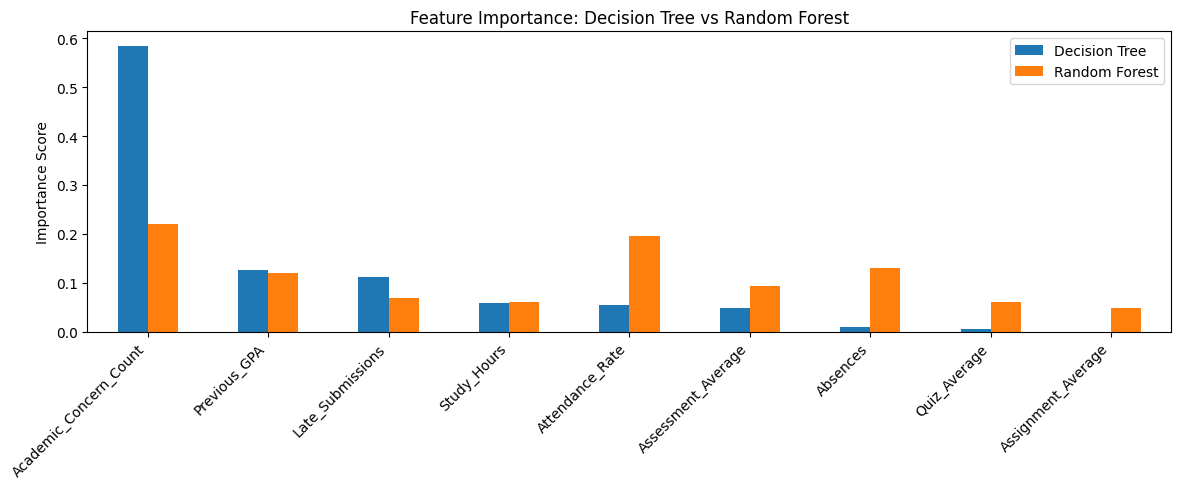

In [23]:

# STEP 9: Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

dt_importance = pd.Series(
    dt_pipeline.named_steps["classifier"].feature_importances_,
    index=feature_columns,
    name="Decision Tree"
)

rf_importance = pd.Series(
    rf_pipeline.named_steps["classifier"].feature_importances_,
    index=feature_columns,
    name="Random Forest"
)

importance_df = pd.concat(
    [dt_importance, rf_importance], axis=1
)

importance_df = importance_df.sort_values(
    by="Decision Tree", ascending=False
)

print("FEATURE IMPORTANCE TABLE")
display(importance_df.round(3))

importance_df.plot(kind="bar", figsize=(12, 5))
plt.title("Feature Importance: Decision Tree vs Random Forest")
plt.ylabel("Importance Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [24]:

# STEP 10: Five fictional student predictions

sample_cases = pd.DataFrame({
    "Attendance_Rate": [95, 60, 72, 85, 55],
    "Quiz_Average": [90, 50, 68, 78, 45],
    "Assignment_Average": [92, 55, 65, 82, 50],
    "Absences": [1, 8, 5, 3, 10],
    "Late_Submissions": [0, 6, 3, 2, 7],
    "Study_Hours": [20, 4, 8, 15, 3],
    "Previous_GPA": [2.0, 3.5, 2.8, 2.3, 3.7]
})

sample_cases["Assessment_Average"] = (
    sample_cases["Quiz_Average"] +
    sample_cases["Assignment_Average"]
) / 2

sample_cases["Academic_Concern_Count"] = (
    (sample_cases["Attendance_Rate"] < 75).astype(int) +
    (sample_cases["Quiz_Average"] < 70).astype(int) +
    (sample_cases["Assignment_Average"] < 70).astype(int) +
    (sample_cases["Absences"] >= 5).astype(int)
)

sample_cases.insert(
    0, "Student_ID",
    ["SAMPLE-01", "SAMPLE-02", "SAMPLE-03",
     "SAMPLE-04", "SAMPLE-05"]
)

sample_cases["Decision_Tree_Prediction"] = (
    dt_pipeline.predict(sample_cases[feature_columns])
)

sample_cases["Random_Forest_Prediction"] = (
    rf_pipeline.predict(sample_cases[feature_columns])
)

display(sample_cases.round(2))
print("Note: Fictional practice cases only; predictions are not guaranteed.")


,Student_ID,Attendance_Rate,Quiz_Average,Assignment_Average,Absences,Late_Submissions,Study_Hours,Previous_GPA,Assessment_Average,Academic_Concern_Count,Decision_Tree_Prediction,Random_Forest_Prediction
0,SAMPLE-01,95,90,92,1,0,20,2.0,91.0,0,Satisfactory,Satisfactory
1,SAMPLE-02,60,50,55,8,6,4,3.5,52.5,4,At Risk,At Risk
2,SAMPLE-03,72,68,65,5,3,8,2.8,66.5,4,At Risk,At Risk
3,SAMPLE-04,85,78,82,3,2,15,2.3,80.0,0,Satisfactory,Satisfactory
4,SAMPLE-05,55,45,50,10,7,3,3.7,47.5,4,At Risk,At Risk


Note: Fictional practice cases only; predictions are not guaranteed.


# PART A: BUSINESS PROBLEM AND DATA UNDERSTANDING

## 1. Business Problem

The university needs a decision-support system that identifies students who may require early academic support. The system uses information available at the midterm checkpoint to predict whether a student may be academically at risk.

**Decision-support question:** Which students should be prioritized for academic adviser review based on their attendance, assessment performance, absences, submission history, study hours, and previous GPA?

## 2. Stakeholders

- **Academic Adviser:** Reviews flagged students and records interventions.
- **Faculty Member:** Provides authorized academic records and relevant updates.
- **Program Chair:** Monitors overall risk trends and support activities.
- **System Administrator:** Maintains system access, data security, and model versions.
- **Student:** May receive appropriate academic support after adviser review.

## 3. Prediction Checkpoint

Predictions are generated at the midterm checkpoint using only information available by that time. Final grades and other future information must not be used as predictors.

## 4. Dataset Summary

The practice dataset contains 300 synthetic records and 9 original columns. After adding two derived predictors, the cleaned dataset contains 300 records and 11 columns.

The target distribution is:
- At Risk: 213 records (71%)
- Satisfactory: 87 records (29%)

These are synthetic practice results and must not be interpreted as actual university student outcomes.

# PART D: FUNCTIONAL REQUIREMENTS

| Requirement ID | System shall... | Evidence / Finding | Use Case ID |
|---|---|---|---|
| FR-PM-01 | Load and validate student records before prediction. | The practice dataset was checked for missing values, duplicates, and invalid ranges. | UC-01 |
| FR-PM-02 | Generate academic-risk predictions using the approved model and midterm predictors. | Decision Tree and Random Forest were trained and evaluated. | UC-02 |
| FR-PM-03 | Display the predicted risk and major contributing features to authorized advisers. | Feature importance is available from the trained classifiers. | UC-03 |
| FR-PM-04 | Allow authorized advisers to record their review decision and intervention. | Predictions are intended to support human review, not automatic adverse decisions. | UC-04 |
| FR-PM-05 | Record prediction timestamps and model versions for accountability. | Model outputs must be traceable to the model used. | UC-05 |

## NON-FUNCTIONAL REQUIREMENTS

1. **Privacy:** Only authenticated, authorized users shall access identifiable student records; access attempts shall be logged.
2. **Performance:** The system shall display predictions for a batch of 400 records within 10 seconds under the specified test environment.
3. **Reliability:** The system shall retain prediction and intervention audit records and provide a recoverable backup at least once every 24 hours.

These are proposed system requirements and must be tested during implementation.

# USE CASE SPECIFICATION

## UC-02: Generate and Review Academic Risk Predictions

**Primary Actor:** Academic Adviser

**Supporting Actors:** Faculty Member, Program Chair, System Administrator

**Trigger:** The Academic Adviser opens the midterm academic-risk dashboard and requests the latest predictions.

**Preconditions:**
1. The adviser is authenticated and authorized.
2. Midterm student records are available.
3. The approved model version is registered and available.
4. Required data validation checks have been completed.

**Main Flow:**
1. The Academic Adviser signs in to the system.
2. The system verifies the adviser's access permissions.
3. The adviser opens the academic-risk dashboard.
4. The adviser selects the midterm checkpoint and requests predictions.
5. The system validates the available student records.
6. The preprocessing pipeline prepares the approved predictor fields.
7. The model generates a predicted status for each eligible student.
8. The system records the prediction timestamp and model version.
9. The dashboard displays predicted risk, major risk indicators, and review status.
10. The adviser reviews the student's available academic information.
11. The adviser records a human decision and any intervention provided.
12. The system saves the review record for authorized follow-up.

**Alternative Flows:**

- **A1 — Missing or incomplete record:** The system flags the record for correction and excludes it from prediction until required information is resolved.
- **A2 — Adviser disagrees with prediction:** The adviser records the reason for disagreement, the final human decision, and any appropriate follow-up action.

**Exception:**

- **E1 — Model unavailable:** The system displays an error, records the failed prediction attempt, and instructs the user to contact the System Administrator. No unsupported prediction is displayed as valid.

**Postconditions:**
- Predictions and model versions are recorded.
- The adviser's final decision and intervention are saved when provided.
- Records remain accessible only to authorized users.
- Predictions do not automatically impose penalties or other adverse decisions.

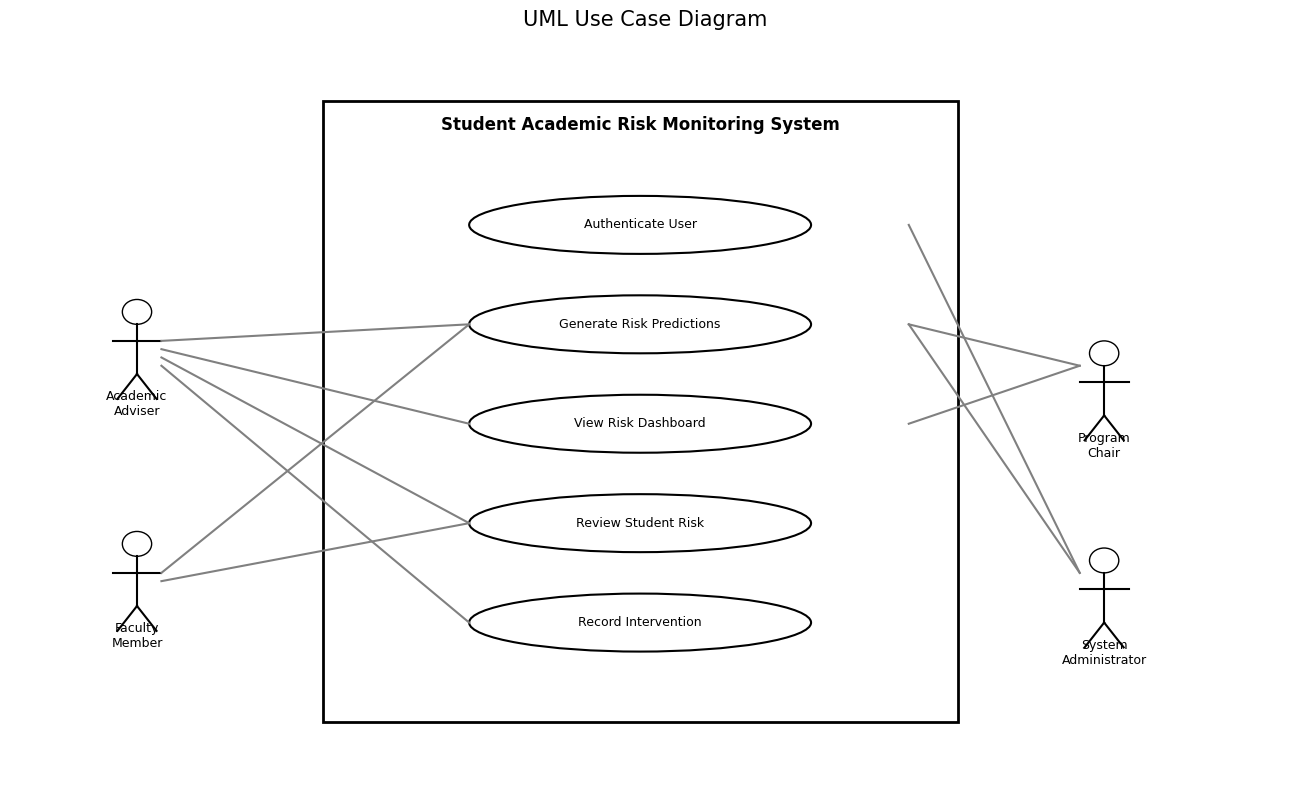

In [25]:

# STEP 14: UML Use Case Diagram

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Rectangle

fig, ax = plt.subplots(figsize=(13, 8))
ax.set_xlim(0, 13)
ax.set_ylim(0, 9)
ax.axis("off")

# System boundary
ax.add_patch(Rectangle((3.2, 0.7), 6.5, 7.5,
                       fill=False, linewidth=2))
ax.text(6.45, 7.85, "Student Academic Risk Monitoring System",
        ha="center", fontsize=12, weight="bold")

# Use cases
use_cases = [
    (6.45, 6.7, "Authenticate User"),
    (6.45, 5.5, "Generate Risk Predictions"),
    (6.45, 4.3, "View Risk Dashboard"),
    (6.45, 3.1, "Review Student Risk"),
    (6.45, 1.9, "Record Intervention"),
]

for x, y, label in use_cases:
    ax.add_patch(Ellipse((x, y), 3.5, 0.7,
                         fill=False, linewidth=1.5))
    ax.text(x, y, label, ha="center", va="center", fontsize=9)

# Actors
actors = [
    (1.3, 5.5, "Academic\nAdviser"),
    (1.3, 2.7, "Faculty\nMember"),
    (11.2, 5.0, "Program\nChair"),
    (11.2, 2.5, "System\nAdministrator"),
]

for x, y, label in actors:
    ax.plot([x, x], [y, y - 0.6], color="black")
    ax.plot([x - 0.25, x + 0.25], [y - 0.2, y - 0.2],
            color="black")
    ax.plot([x, x - 0.2], [y - 0.6, y - 0.9], color="black")
    ax.plot([x, x + 0.2], [y - 0.6, y - 0.9], color="black")
    ax.add_patch(plt.Circle((x, y + 0.15), 0.15,
                            fill=False, color="black"))
    ax.text(x, y - 1.1, label, ha="center", fontsize=9)

# Actor associations
ax.plot([1.55, 4.7], [5.3, 5.5], color="gray")
ax.plot([1.55, 4.7], [5.2, 4.3], color="gray")
ax.plot([1.55, 4.7], [5.1, 3.1], color="gray")
ax.plot([1.55, 4.7], [5.0, 1.9], color="gray")
ax.plot([1.55, 4.7], [2.5, 5.5], color="gray")
ax.plot([1.55, 4.7], [2.4, 3.1], color="gray")
ax.plot([9.2, 10.95], [5.5, 5.0], color="gray")
ax.plot([9.2, 10.95], [4.3, 5.0], color="gray")
ax.plot([9.2, 10.95], [6.7, 2.5], color="gray")
ax.plot([9.2, 10.95], [5.5, 2.5], color="gray")

plt.title("UML Use Case Diagram", fontsize=15)
plt.tight_layout()
plt.show()


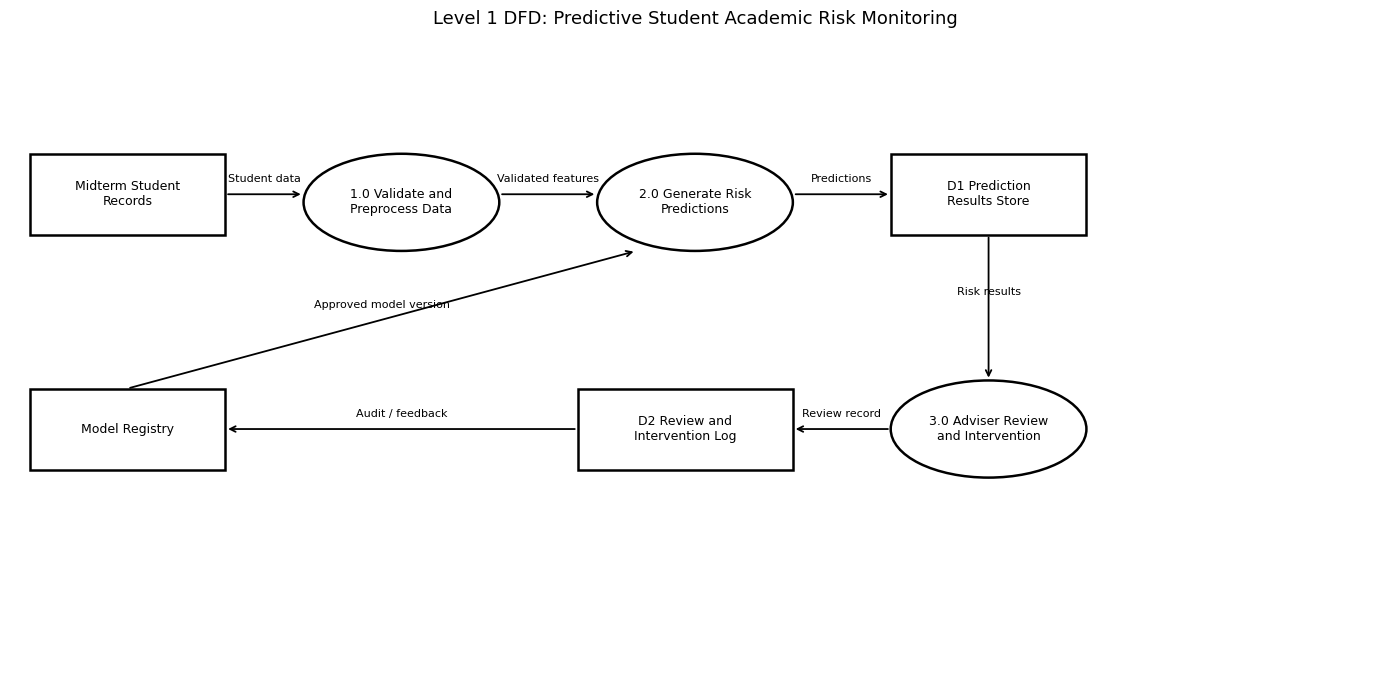

In [26]:

# STEP 15: Level 1 Data Flow Diagram

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch

fig, ax = plt.subplots(figsize=(14, 7))
ax.set_xlim(0, 14)
ax.set_ylim(0, 8)
ax.axis("off")

def process(x, y, w, h, text):
    ax.add_patch(Ellipse((x + w/2, y + h/2), w, h,
                         fill=False, linewidth=1.8))
    ax.text(x + w/2, y + h/2, text,
            ha="center", va="center", fontsize=9)

def store(x, y, w, h, text):
    ax.add_patch(Rectangle((x, y), w, h,
                           fill=False, linewidth=1.8))
    ax.text(x + w/2, y + h/2, text,
            ha="center", va="center", fontsize=9)

def arrow(x1, y1, x2, y2, label):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", linewidth=1.3))
    ax.text((x1+x2)/2, (y1+y2)/2 + 0.15, label,
            ha="center", fontsize=8)

store(0.2, 5.5, 2.0, 1.0, "Midterm Student\nRecords")
process(3.0, 5.3, 2.0, 1.2, "1.0 Validate and\nPreprocess Data")
process(6.0, 5.3, 2.0, 1.2, "2.0 Generate Risk\nPredictions")
store(9.0, 5.5, 2.0, 1.0, "D1 Prediction\nResults Store")
process(9.0, 2.5, 2.0, 1.2, "3.0 Adviser Review\nand Intervention")
store(5.8, 2.6, 2.2, 1.0, "D2 Review and\nIntervention Log")
store(0.2, 2.6, 2.0, 1.0, "Model Registry")

arrow(2.2, 6.0, 3.0, 6.0, "Student data")
arrow(5.0, 6.0, 6.0, 6.0, "Validated features")
arrow(8.0, 6.0, 9.0, 6.0, "Predictions")
arrow(10.0, 5.5, 10.0, 3.7, "Risk results")
arrow(9.0, 3.1, 8.0, 3.1, "Review record")
arrow(5.8, 3.1, 2.2, 3.1, "Audit / feedback")
arrow(1.2, 3.6, 6.4, 5.3, "Approved model version")

plt.title("Level 1 DFD: Predictive Student Academic Risk Monitoring",
          fontsize=13)
plt.tight_layout()
plt.show()


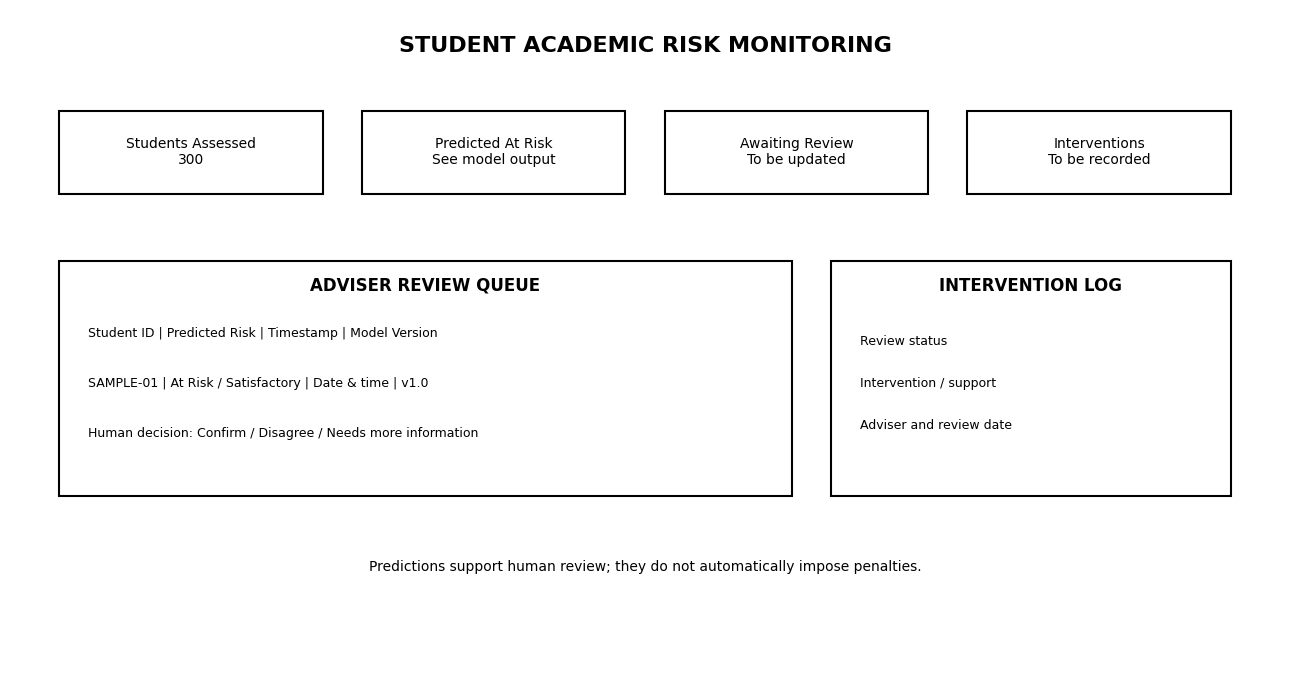

In [27]:

# STEP 16: Academic Risk Dashboard Wireframe

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(13, 7))
ax.set_xlim(0, 13)
ax.set_ylim(0, 8)
ax.axis("off")

# Dashboard title
ax.text(6.5, 7.5, "STUDENT ACADEMIC RISK MONITORING",
        ha="center", fontsize=16, weight="bold")

# Summary cards
cards = [
    (0.5, 5.8, 2.7, 1.0, "Students Assessed\n300"),
    (3.6, 5.8, 2.7, 1.0, "Predicted At Risk\nSee model output"),
    (6.7, 5.8, 2.7, 1.0, "Awaiting Review\nTo be updated"),
    (9.8, 5.8, 2.7, 1.0, "Interventions\nTo be recorded"),
]

for x, y, w, h, label in cards:
    ax.add_patch(Rectangle((x, y), w, h, fill=False, linewidth=1.5))
    ax.text(x + w/2, y + h/2, label,
            ha="center", va="center", fontsize=10)

# Review queue
ax.add_patch(Rectangle((0.5, 2.2), 7.5, 2.8,
                       fill=False, linewidth=1.5))
ax.text(4.25, 4.65, "ADVISER REVIEW QUEUE",
        ha="center", weight="bold", fontsize=12)
ax.text(0.8, 4.1,
        "Student ID | Predicted Risk | Timestamp | Model Version",
        fontsize=9)
ax.text(0.8, 3.5,
        "SAMPLE-01 | At Risk / Satisfactory | Date & time | v1.0",
        fontsize=9)
ax.text(0.8, 2.9,
        "Human decision: Confirm / Disagree / Needs more information",
        fontsize=9)

# Intervention log
ax.add_patch(Rectangle((8.4, 2.2), 4.1, 2.8,
                       fill=False, linewidth=1.5))
ax.text(10.45, 4.65, "INTERVENTION LOG",
        ha="center", weight="bold", fontsize=12)
ax.text(8.7, 4.0, "Review status", fontsize=9)
ax.text(8.7, 3.5, "Intervention / support", fontsize=9)
ax.text(8.7, 3.0, "Adviser and review date", fontsize=9)
ax.text(6.5, 1.3,
        "Predictions support human review; they do not automatically impose penalties.",
        ha="center", fontsize=10)

plt.tight_layout()
plt.show()


# PART E: CRITICAL REFLECTION AND TRACEABILITY

## 1. Data-Quality Limitation

The dataset used in this practice exercise is synthetic and contains no missing values or duplicate records. Real university data may contain incomplete, outdated, inconsistent, or incorrectly encoded records. Therefore, the observed model performance may not generalize to actual students.

## 2. Fairness and Privacy Risk

Students with different personal, financial, accessibility, or learning circumstances may have different patterns of attendance and assessment performance. A model could flag students unfairly if these patterns are interpreted without context. Identifiable academic records must be restricted to authorized personnel, and predictions must be reviewed by a human adviser.

## 3. Procedure for Incorrect Predictions

When a student or adviser identifies a potentially incorrect prediction:
1. Mark the case for review.
2. Verify the source academic records.
3. Record the reason for disagreement.
4. Allow an authorized adviser to determine the appropriate support action.
5. Correct inaccurate source data and rerun the approved prediction when appropriate.
6. Retain an audit trail of the original prediction, correction, review decision, and intervention.

## 4. Traceability Table

| Business Problem | Data | Model Finding | Requirement | Use Case | Dashboard Element |
|---|---|---|---|---|---|
| Identify students needing early support | Attendance and assessment scores | Compare positive-class recall | FR-PM-02: Generate risk predictions | UC-02: Generate predictions | Predicted risk |
| Help advisers prioritize review | Absences and derived concern indicators | Review feature importance | FR-PM-03: Display risk factors | UC-03: View and review risk | Adviser review queue |
| Ensure accountable decisions | Prediction timestamp and model version | Predictions may be incorrect | FR-PM-04: Record interventions | UC-04: Record intervention | Intervention log |
| Support audit and traceability | Prediction and review records | Model performance varies | FR-PM-05: Record version and timestamp | UC-05: Audit predictions | Prediction details |

## 5. Model Recommendation

In this synthetic experiment, the Decision Tree achieved 98.3% accuracy, 97.7% precision, 100% recall, and a 98.9% F1-score. It produced zero false negatives and one false positive on the 60-record test set. The Random Forest achieved 91.7% accuracy, 91.3% precision, 97.7% recall, and a 94.4% F1-score, with one false negative and four false positives.

The Decision Tree is the preliminary choice for adviser review in this experiment because it performed better on the held-out synthetic test set and is relatively interpretable. However, the synthetic labels were generated from rules related to the predictors, so this performance does not establish real-world effectiveness. The model must be validated on suitable real-world data, reviewed for fairness, and monitored before any operational deployment.

In [28]:

from google.colab import files

files.download("student_performance_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>